# k-clique communities — *Os Maias*

Clique percolation finds overlapping communities: two k-cliques belong to the same community when they can be reached through a chain of k-cliques sharing k−1 nodes. **k is an analyst-chosen resolution parameter, not a true or uniquely correct value.** The weight threshold changes which co-occurrence ties are retained.

The null model independently degree-preserving-rewires each thresholded graph 100 times. Its edge weights are not used by k-clique percolation; they are retained only on the real graph for Louvain and weighted-degree visualization.

## 1. Load and describe the network

In [36]:
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from communities import (
    METRICS, candidate_table, compare_with_louvain, describe_communities,
    find_group_column, plot_nmi_sweep, run_nmi_sweep,
    load_weighted_graph, max_clique_size, plot_community_network,
    plot_metric_heatmap, plot_metric_sweep, run_k_clique_sweep,
    threshold_graph, validate_k_clique_communities,
)

ROOT = Path.cwd()
EDGE_PATH = ROOT / "Data" / "os_maias_cooccurrence_edges.csv"
NODE_PATH = ROOT / "Data" / "os_maias_ground_truth_nodes.csv"
RESULTS_PATH = ROOT / "k_clique_results.csv"
G, name_map = load_weighted_graph(EDGE_PATH, NODE_PATH)
NODE_DATA = pd.read_csv(NODE_PATH, dtype={"id": str})
GROUP_COLUMN = find_group_column(NODE_DATA)
NMI_RESULTS_PATH = ROOT / "k_clique_nmi_results.csv"
print(f"Group annotation column: {GROUP_COLUMN or 'none with usable values'}")
n, m = G.number_of_nodes(), G.number_of_edges()
print({"nodes": n, "edges": m, "density": nx.density(G),
       "max_clique_size": max_clique_size(G)})

Group annotation column: none with usable values
{'nodes': 103, 'edges': 663, 'density': 0.1262135922330097, 'max_clique_size': 12}


## 2. Sweep k and edge-weight thresholds

All randomization seeds are fixed: base seed 4200, offset by threshold and replicate for null graphs; the Louvain comparison uses seeds 41–45; the visualization layout uses seed 42. Each threshold's null graphs are generated once and reused for all k. This requested 400-graph null sweep can take several minutes; progress is printed every 10 shuffles.

In [37]:
THRESHOLDS = (1, 2, 3, 5)
N_SHUFFLES = 100
SWAPS_PER_EDGE = 10
BASE_SEED = 4200

results = run_k_clique_sweep(
    G, thresholds=THRESHOLDS, n_shuffles=N_SHUFFLES,
    swaps_per_edge=SWAPS_PER_EDGE, seed=BASE_SEED,
)
results.to_csv(RESULTS_PATH, index=False)
print(f"Saved {len(results)} (k, w_min) rows to {RESULTS_PATH}")
display(results.head())

w_min=1: generating 100 null graphs (10 swaps per edge)...


KeyboardInterrupt: 

For every metric, `*_null_mean`, `*_null_std`, and `*_z_score` summarize the shuffled graphs; `*_p_ge` and `*_p_le` are empirical tail fractions. The standard deviation uses the population convention (`ddof=0`). A zero null standard deviation yields an undefined (`NaN`) z-score rather than division by zero. Rows with no real communities have `status='none'` and zero-valued community metrics.

## 3. Candidate settings and recommended k

In [ ]:
# Editable candidate criteria (all must hold).
MIN_COMMUNITIES = 3
MAX_GIANT_FRACTION = 0.90
MIN_COVERAGE_PCT = 50.0
MIN_OVERLAP_NODES = 3
MIN_ABS_Z = 2.0
MAX_EMPIRICAL_P = 0.05

ranked = candidate_table(
    results, min_communities=MIN_COMMUNITIES,
    max_giant_fraction=MAX_GIANT_FRACTION,
    min_coverage_pct=MIN_COVERAGE_PCT,
    min_overlap_nodes=MIN_OVERLAP_NODES, min_abs_z=MIN_ABS_Z,
    max_empirical_p=MAX_EMPIRICAL_P,
)
summary_columns = [
    "k", "w_min", "num_communities", "num_communities_null_mean",
    "num_communities_z_score", "num_communities_p_ge", "num_communities_p_le",
    "giant_fraction", "giant_fraction_null_mean", "giant_fraction_z_score",
    "giant_fraction_p_ge", "giant_fraction_p_le",
    "coverage_pct", "coverage_pct_null_mean", "coverage_pct_z_score",
    "coverage_pct_p_ge", "coverage_pct_p_le", "overlap_nodes",
    "overlap_nodes_null_mean", "overlap_nodes_z_score",
    "overlap_nodes_p_ge", "overlap_nodes_p_le", "covered_nodes_z_score",
    "covered_nodes_p_ge", "covered_nodes_p_le", "criteria_passed", "candidate",
]
summary = ranked.sort_values(["w_min", "k"])[summary_columns]
display(summary.style.apply(
    lambda row: ["background-color: #d9ead3" if ranked.loc[row.name, "candidate"]
                 else "" for _ in row], axis=1
).format(precision=3))

# Candidate rank uses criteria count, then coverage, then overlap; z/p are not ranking scores.
recommendations = ranked[ranked["candidate"]].head(3)
if recommendations.empty:
    recommendations = ranked.head(3)
    print("No setting satisfies every criterion; showing the best-ranked settings.")
for rank, row in enumerate(recommendations.itertuples(), start=1):
    p_value = min(row.covered_nodes_p_ge, row.covered_nodes_p_le,
                  row.num_communities_p_ge, row.num_communities_p_le)
    print(f"{rank}. k={row.k}, w_min={row.w_min}: {row.criteria_passed}/5 criteria, "
          f"{row.coverage_pct:.1f}% coverage, {row.overlap_nodes} overlap nodes, "
          f"|z_covered|={abs(row.covered_nodes_z_score):.2f}, "
          f"|z_communities|={abs(row.num_communities_z_score):.2f}, "
          f"minimum empirical tail p={p_value:.3f}; "
          f"{'candidate' if row.candidate else 'not a full candidate'}.")

,k,w_min,num_communities,num_communities_null_mean,num_communities_z_score,num_communities_p_ge,num_communities_p_le,giant_fraction,giant_fraction_null_mean,giant_fraction_z_score,giant_fraction_p_ge,giant_fraction_p_le,coverage_pct,coverage_pct_null_mean,coverage_pct_z_score,coverage_pct_p_ge,coverage_pct_p_le,overlap_nodes,overlap_nodes_null_mean,overlap_nodes_z_score,overlap_nodes_p_ge,overlap_nodes_p_le,covered_nodes_z_score,covered_nodes_p_ge,covered_nodes_p_le,criteria_passed,candidate
22,3,1,1,1.010,-0.101,1.000,0.990,1.000,1.000,0.101,0.990,1.000,95.146,93.184,1.650,0.080,1.000,0,0.010,-0.101,1.000,0.990,1.650,0.080,1.000,1,False
16,4,1,2,1.020,7.000,0.020,1.000,0.957,1.000,-15.972,1.000,0.000,89.320,80.340,3.942,0.000,1.000,2,0.050,5.461,0.020,0.990,3.942,0.000,1.000,2,False
17,5,1,2,1.020,7.000,0.020,1.000,0.960,1.000,-17.857,1.000,0.000,72.816,63.068,4.798,0.000,1.000,2,0.090,3.013,0.020,0.980,4.798,0.000,1.000,2,False
1,6,1,2,1.090,3.180,0.090,1.000,0.892,0.998,-15.089,1.000,0.000,63.107,50.583,6.008,0.000,1.000,4,0.450,2.457,0.090,0.930,6.008,0.000,1.000,4,False
2,7,1,2,1.160,2.011,0.140,0.980,0.895,0.997,-9.179,1.000,0.000,55.340,39.544,6.040,0.000,1.000,3,0.960,0.837,0.140,0.860,6.040,0.000,1.000,4,False
3,8,1,3,1.490,1.792,0.110,0.940,0.820,0.969,-2.072,0.960,0.040,48.544,28.981,5.864,0.000,1.000,7,2.770,0.969,0.230,0.850,5.864,0.000,1.000,4,False
6,9,1,2,1.580,0.463,0.470,0.870,0.861,0.853,0.035,0.650,0.350,34.951,17.786,2.793,0.000,1.000,7,4.070,0.639,0.410,0.660,2.793,0.000,1.000,3,False
7,10,1,2,0.690,1.620,0.130,0.970,0.839,0.493,0.723,0.440,0.560,30.097,6.932,3.303,0.000,1.000,5,1.070,1.354,0.120,0.880,3.303,0.000,1.000,3,False
29,11,1,1,0.110,2.592,0.100,0.990,1.000,0.098,3.058,0.090,1.000,22.330,1.291,5.335,0.000,1.000,0,0.080,-0.101,1.000,0.990,5.335,0.000,1.000,1,False
30,12,1,1,0.020,7.000,0.020,1.000,1.000,0.020,7.000,0.020,1.000,19.417,0.262,10.374,0.000,1.000,0,0.000,nan,1.000,1.000,10.374,0.000,1.000,1,False


1. k=5, w_min=2: 5/5 criteria, 57.3% coverage, 6 overlap nodes, |z_covered|=4.59, |z_communities|=21.29, minimum empirical tail p=0.000; candidate.


## 4. NMI sweep and overlap sensitivity

For settings with at least two k-clique communities, compare the primary-community labels (overlap nodes go to their first, largest community) with five weighted Louvain runs on covered nodes. The baseline shuffles those k-clique labels 200 times using seed 5200. The sensitivity analysis repeats both calculations after excluding overlap nodes. Single-community rows are retained but masked because NMI is not informative there. The group-label NMI is populated only for the two final settings if a usable family/group/social-circle column exists.

Saved NMI sweep to c:\Users\lenovo\OneDrive\Documentos\Uni\DTU - Master in Business Analytics\Social Graphs\SGI-Project\k_clique_nmi_results.csv
Group NMI unavailable: the node file has no non-empty family/group/social-circle labels.


,k,w_min,num_communities,coverage_pct,nmi_nodes,non_overlap_nodes,nmi_status,nmi_covered_real_mean,nmi_covered_real_std,nmi_covered_shuffle_mean,nmi_covered_shuffle_std,louvain_pairwise_nmi_covered,nmi_no_overlap_real_mean,nmi_no_overlap_real_std,nmi_no_overlap_shuffle_mean,nmi_no_overlap_shuffle_std,louvain_pairwise_nmi_no_overlap,group_nmi
0,3,1,1,95.145631,NaN,NaN,masked_single_community,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,4,1,2,89.320388,92.0,90.0,ok,0.051667,2.453935e-03,0.031783,0.017173,0.912767,0.054391,0.002683,0.028545,0.014944,0.912115,NaN
2,5,1,2,72.815534,75.0,73.0,ok,0.055463,3.099412e-03,0.035685,0.015748,0.920742,0.059568,0.003513,0.035721,0.016973,0.919940,NaN
3,6,1,2,63.106796,65.0,61.0,ok,0.100960,1.845554e-02,0.039292,0.021273,0.914230,0.110642,0.019793,0.040950,0.024062,0.911673,NaN
4,7,1,2,55.339806,57.0,54.0,ok,0.112297,1.189071e-02,0.046367,0.025439,0.933319,0.121140,0.010986,0.045526,0.023533,0.931711,NaN
5,8,1,3,48.543689,50.0,43.0,ok,0.222951,1.342918e-02,0.088655,0.032551,0.928160,0.280141,0.015694,0.098750,0.034761,0.919146,NaN
6,9,1,2,34.951456,36.0,29.0,ok,0.149802,3.442342e-04,0.070680,0.035008,0.966837,0.278868,0.000736,0.084130,0.043500,0.961326,NaN
7,10,1,2,30.097087,31.0,26.0,ok,0.158520,1.241267e-17,0.091619,0.044377,1.000000,0.251101,0.000000,0.093820,0.049339,1.000000,NaN
8,11,1,1,22.330097,NaN,NaN,masked_single_community,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,12,1,1,19.417476,NaN,NaN,masked_single_community,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,k,w_min,num_communities,coverage_pct,nmi_nodes,non_overlap_nodes,nmi_status,nmi_covered_real_mean,nmi_covered_real_std,nmi_covered_shuffle_mean,nmi_covered_shuffle_std,louvain_pairwise_nmi_covered,nmi_no_overlap_real_mean,nmi_no_overlap_real_std,nmi_no_overlap_shuffle_mean,nmi_no_overlap_shuffle_std,louvain_pairwise_nmi_no_overlap,group_nmi
12,5,2,4,57.281553,59.0,53.0,ok,0.184769,0.015522,0.105636,0.021188,0.798489,0.221143,0.023973,0.115224,0.02598,0.790435,NaN
25,8,3,3,26.213592,27.0,21.0,ok,0.307744,0.010697,0.152718,0.054479,0.805706,0.526795,0.060165,0.196820,0.06350,0.784751,NaN


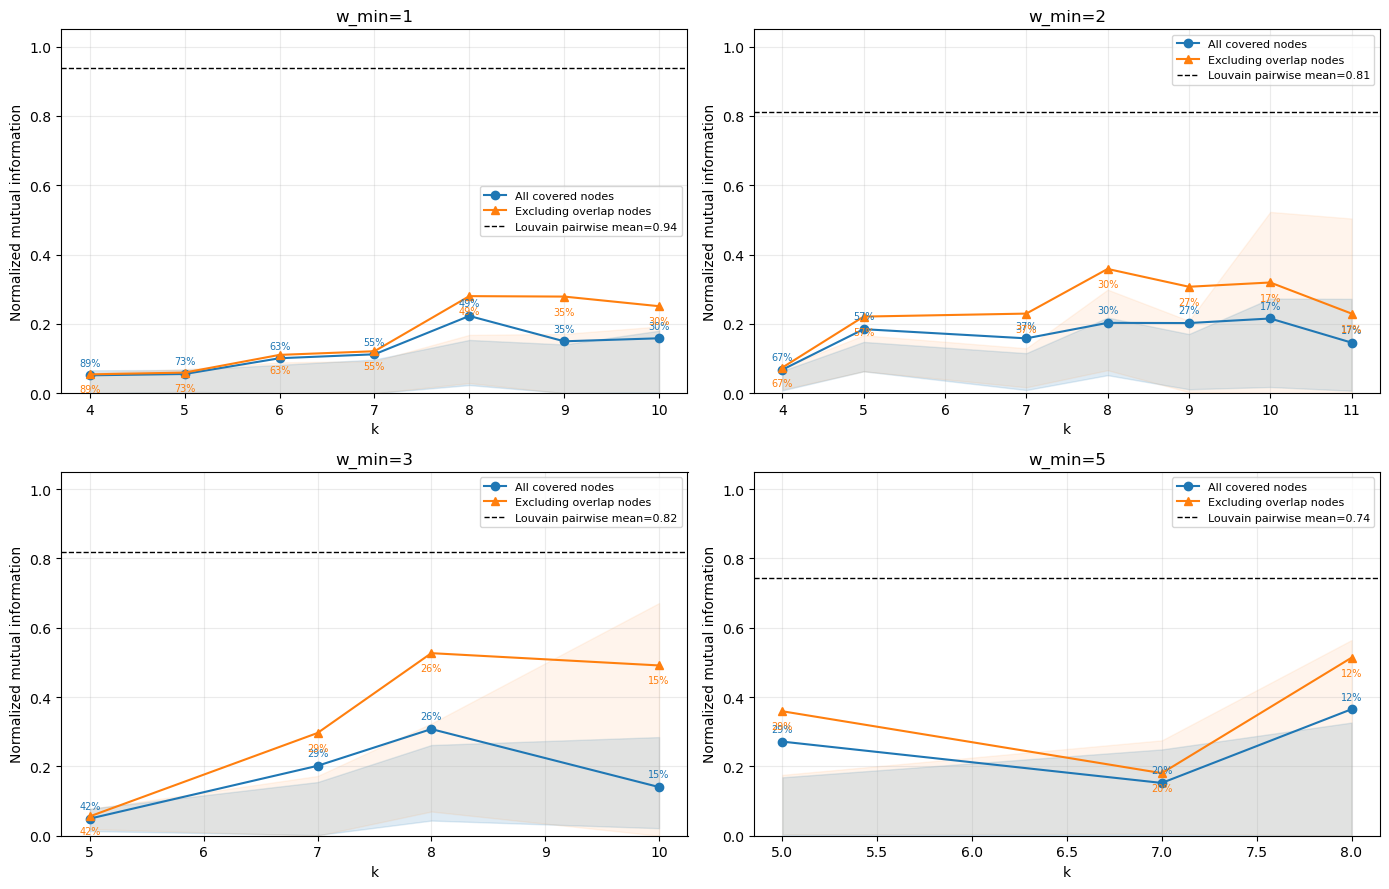

In [ ]:
N_LABEL_SHUFFLES = 200
NMI_SEED = 5200
nmi_results = run_nmi_sweep(
    G, results, n_label_shuffles=N_LABEL_SHUFFLES,
    seeds=(41, 42, 43, 44, 45), seed=NMI_SEED,
    node_data=NODE_DATA, group_column=GROUP_COLUMN,
    group_settings=((5, 2), (8, 3)),
)
nmi_results.to_csv(NMI_RESULTS_PATH, index=False)
print(f"Saved NMI sweep to {NMI_RESULTS_PATH}")
if GROUP_COLUMN is None:
    print("Group NMI unavailable: the node file has no non-empty family/group/social-circle labels.")
display(nmi_results)
display(nmi_results[nmi_results[["k", "w_min"]].apply(tuple, axis=1).isin([(5, 2), (8, 3)])])
fig, axes = plot_nmi_sweep(nmi_results)
plt.show()

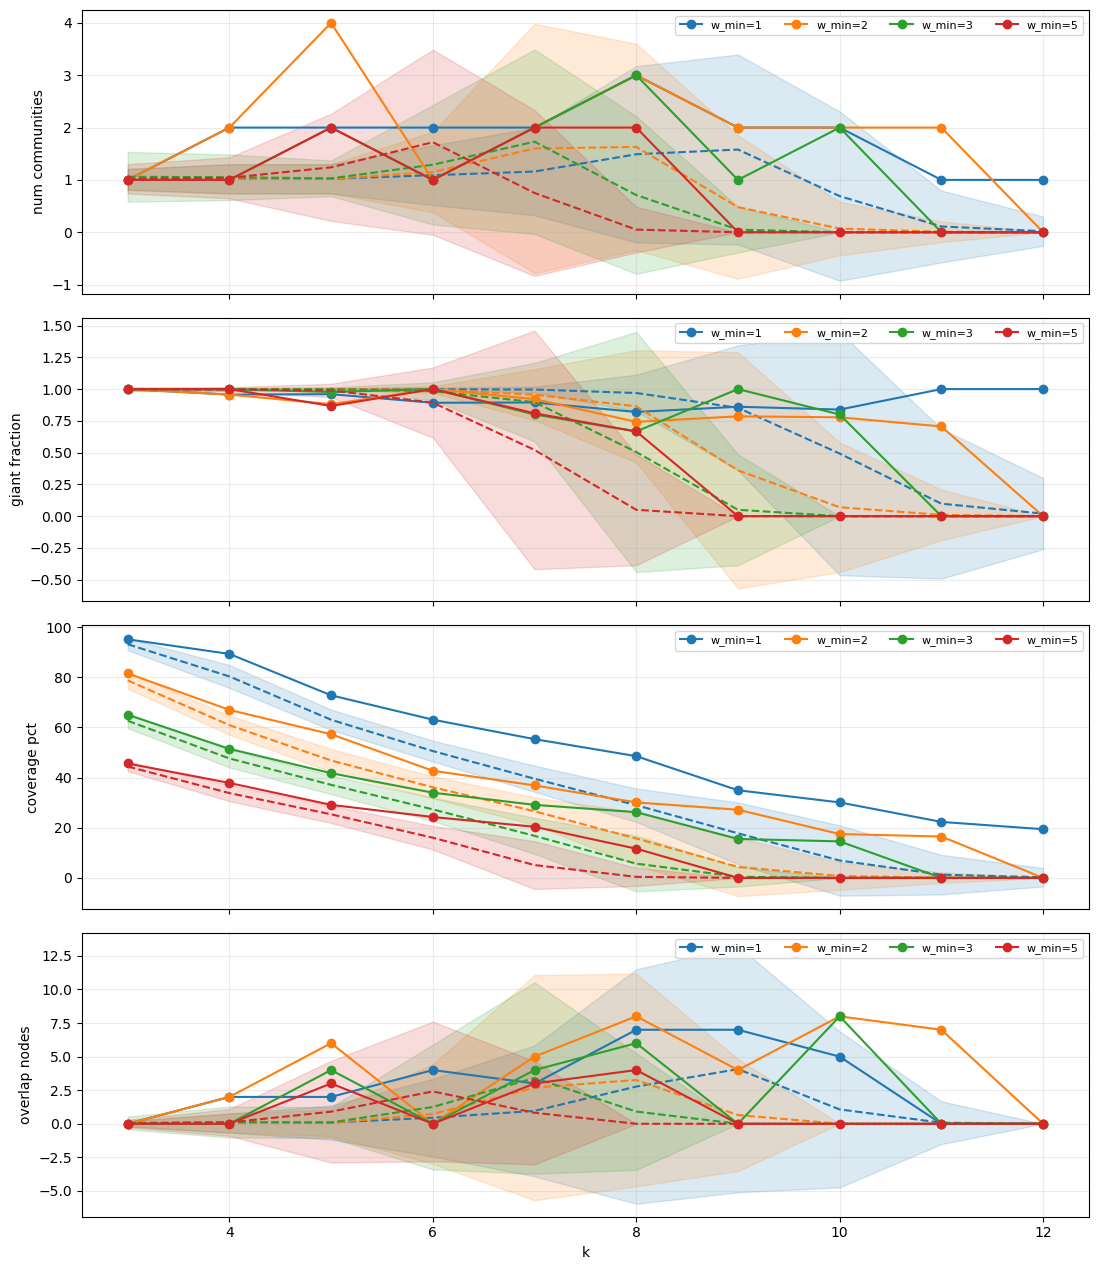

In [ ]:
fig, axes = plot_metric_sweep(results)
plt.show()

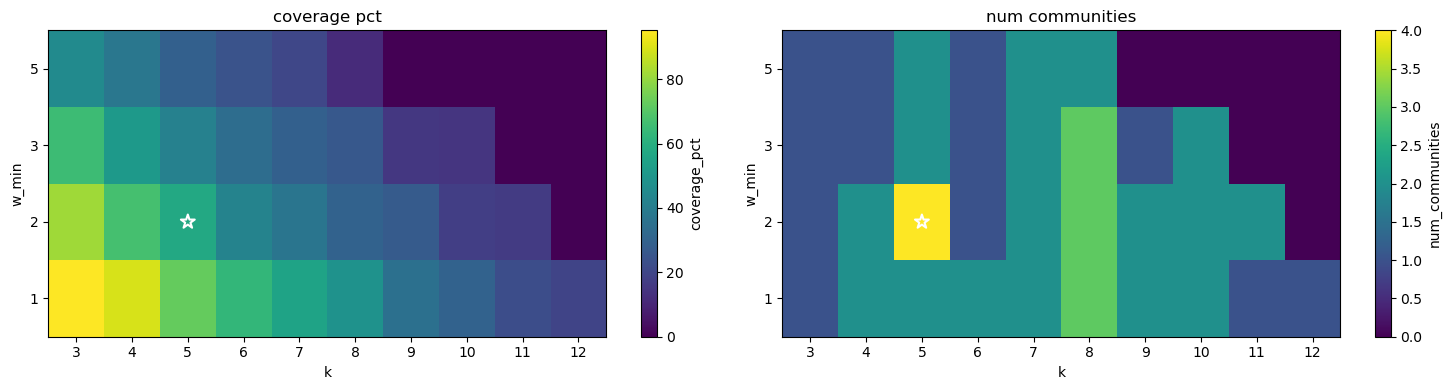

White outlined stars mark settings that pass every candidate criterion.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
plot_metric_heatmap(results, ranked, "coverage_pct", ax=axes[0])
plot_metric_heatmap(results, ranked, "num_communities", ax=axes[1])
plt.tight_layout()
plt.show()
print("White outlined stars mark settings that pass every candidate criterion.")

## 5. Inspect the top three settings

The Louvain comparison reports the mean over five seeds. Since standard NMI needs one label per node, each overlapping k-clique node is assigned to its first community in deterministic largest-community-first order. NMI is computed only on k-clique-covered nodes; pairwise Louvain-run NMI gives a reference for Louvain's own seed stability. Louvain modularity is computed on the full thresholded graph.


=== k=5, w_min=2 ===
Communities (largest first):
  1 (52):  André da Ega, Afonso da Maia, Azevedo, Baptista, Carlos da Maia, Charlie, Clifford, Conde de Gouvarinho, Condessa de Gouvarinho, Craft, Cruges, D. Ana Silveira, D. Diogo Coutinho, D. Maria da Cunha, Darque, Domingos, Dâmaso Salcede, Eusebiozinho Silveira, Gonçalo, Guimarães, Jacob Cohen, Joaquim Álvares de Castro Gomes, João da Ega, Lola, Mac Gren, Manuel Monforte, Maria Eduarda, Maria Monforte, Marquês de Souselas, Melanie, Mendonça, Miss Sara, Mulato, Neves, Niniche, Palma Cavalão, Pedro da Maia, Raquel Cohen, Reverendo Bonifácio, Rosa, Rufino, Sequeira, Sousa Neto, Steinbroken, Taveira, Teixeira, Teles da Gama, Tomás de Alencar, Vargas, Vilaça, Vilaça Júnior, Vladimiro
  2 (5): Afonso da Maia, Brown, Carlos da Maia, Vilaça, abade Custódio
  3 (5):  Conde de Runa, Afonso da Maia, Maria Eduarda Runa, Padre Vasques, Pedro da Maia
  4 (5): Carlos da Maia, D. Ana Silveira, D. Eugénia Silveira, Eusebiozinho Silveira, Teresinha 

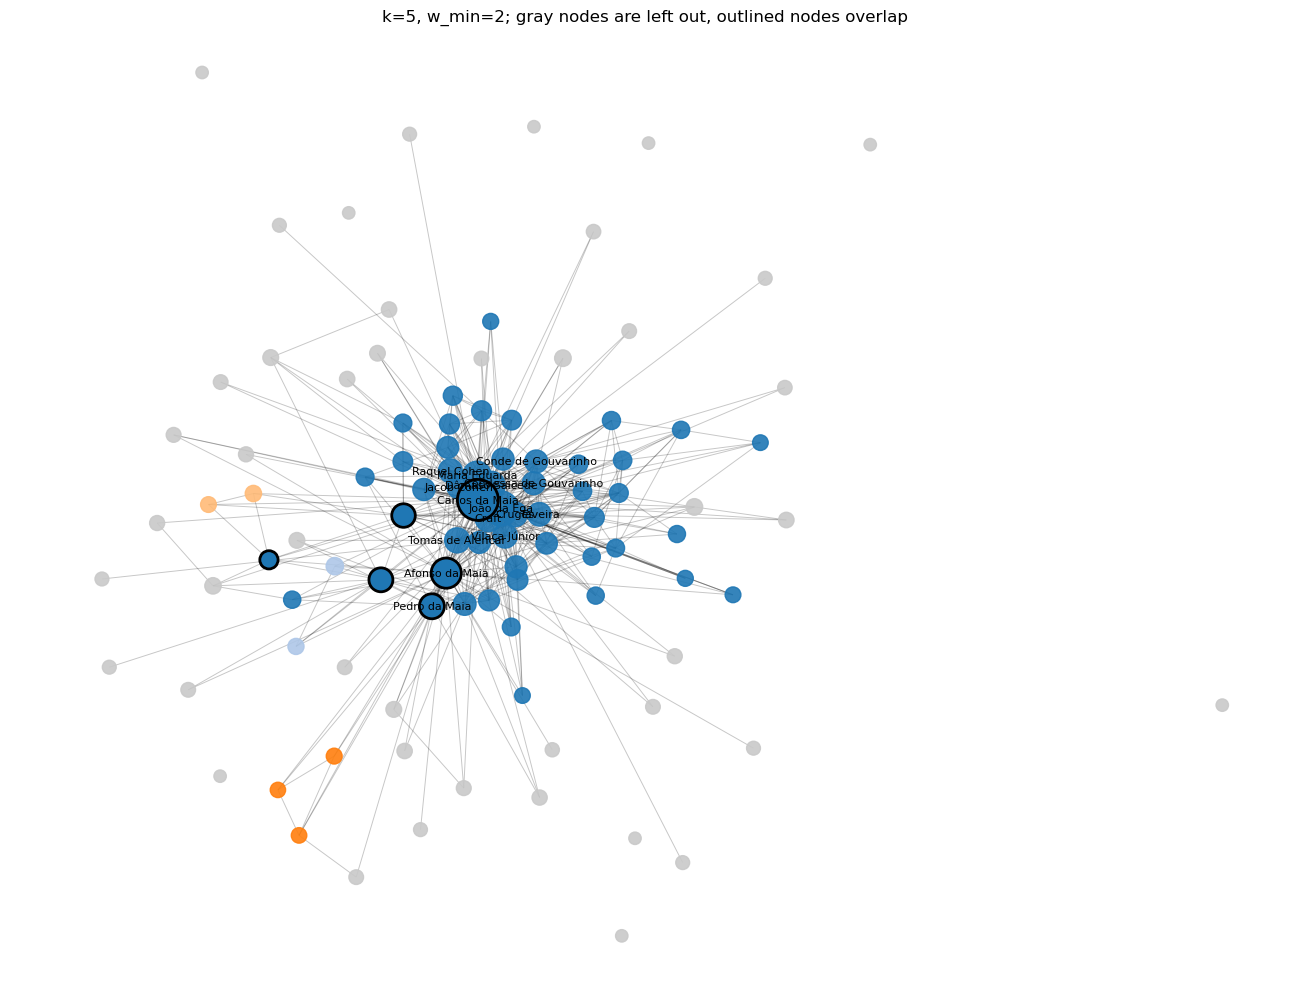

In [ ]:
# One layout for all settings; positions are reused across the network drawings.
layout = nx.spring_layout(G, seed=42, weight="weight")
for row in recommendations.itertuples():
    H = threshold_graph(G, row.w_min)
    detail = describe_communities(H, row.k, name_map)
    print(f"\n=== k={row.k}, w_min={row.w_min} ===")
    print("Communities (largest first):")
    for number, members in enumerate(detail["communities"], start=1):
        print(f"  {number} ({len(members)}): {', '.join(members)}")
    print("Overlap nodes and community numbers:", detail["overlap_nodes"])
    print("Nodes in no community:", ", ".join(detail["uncovered_nodes"]))
    print("Louvain comparison:", compare_with_louvain(H, row.k))
    plot_community_network(H, row.k, name_map, layout, row.w_min)
    plt.show()

## 6. Validate clique construction

The small example consists of two triangles sharing an edge. At k=3 they form one percolated community; the validator checks that each returned community contains at least one complete k-clique.

In [ ]:
example = nx.Graph()
example.add_edges_from([(0, 1), (0, 2), (1, 2), (1, 3), (2, 3)])
assert validate_k_clique_communities(example, 3)
assert len(list(nx.community.k_clique_communities(example, 3))) == 1

# Also validate every real-network community in the recommended settings.
for row in recommendations.itertuples():
    H = threshold_graph(G, row.w_min)
    assert validate_k_clique_communities(H, row.k)
print("Clique construction validation passed.")

Clique construction validation passed.


## How to read these results

The shaded band on each sweep plot is the null-model mean ± 2 standard deviations at the same k and weight threshold; it describes variation after degree-preserving rewiring, not a confidence interval for the observed network. A real value outside that band is more interesting because that metric is less typical of networks with the same degree sequence under this null model. Values inside the band are comparatively compatible with that null, but do not prove the absence of meaningful communities. Consider coverage and overlap alongside significance: a striking score based on very few covered characters may not be useful. Finally, **k is a parameter you choose** to explore community resolution; the data do not provide a single objectively “true” k.

## Final choice

**Chosen setting: k=5, w_min=2.** It gives four communities, covers about 57% of characters, and retains six overlap nodes while keeping the largest-community fraction below the  0.90 limit. Its covered-node and community counts also differ strongly from the degree-preserving null, making it a useful balance of interpretability and coverage.

**Complementary view: k=8, w_min=3.** This stricter, higher-resolution view yields three smaller communities and seven overlap nodes, with a 0.70 giant fraction. Its lower coverage (about 29%) makes it complementary rather than a replacement for the broader k=5 view.

k = 5, w = 2

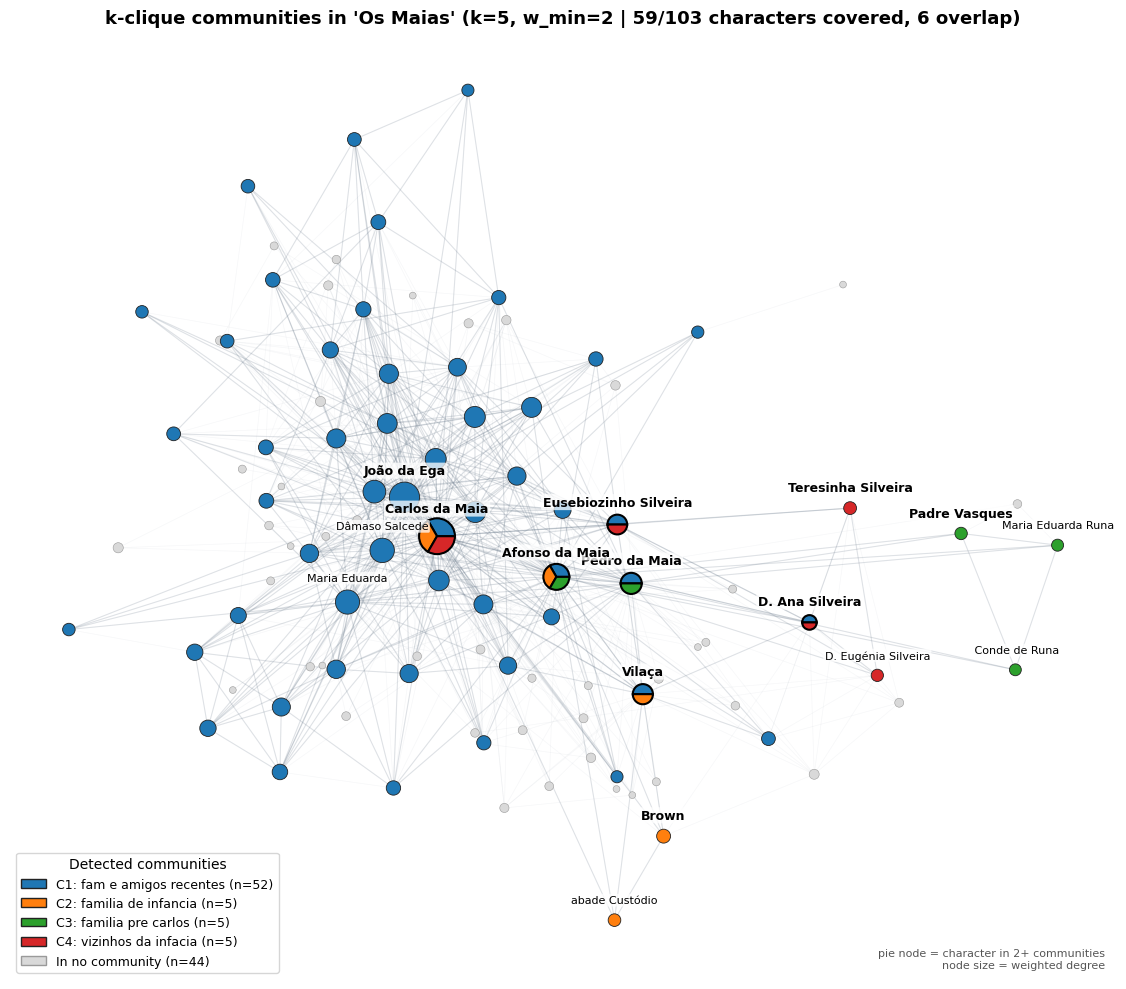

,community,size,members (by weighted degree),overlap members
0,1,52,"Carlos da Maia *, João da Ega, Dâmaso Salcede,...","Carlos da Maia, Afonso da Maia, Pedro da Maia,..."
1,2,5,"Carlos da Maia *, Afonso da Maia *, Vilaça *, ...","Carlos da Maia, Afonso da Maia, Vilaça"
2,3,5,"Afonso da Maia *, Pedro da Maia *, Padre Vasqu...","Afonso da Maia, Pedro da Maia"
3,4,5,"Carlos da Maia *, Eusebiozinho Silveira *, D. ...","Carlos da Maia, Eusebiozinho Silveira, D. Ana ..."


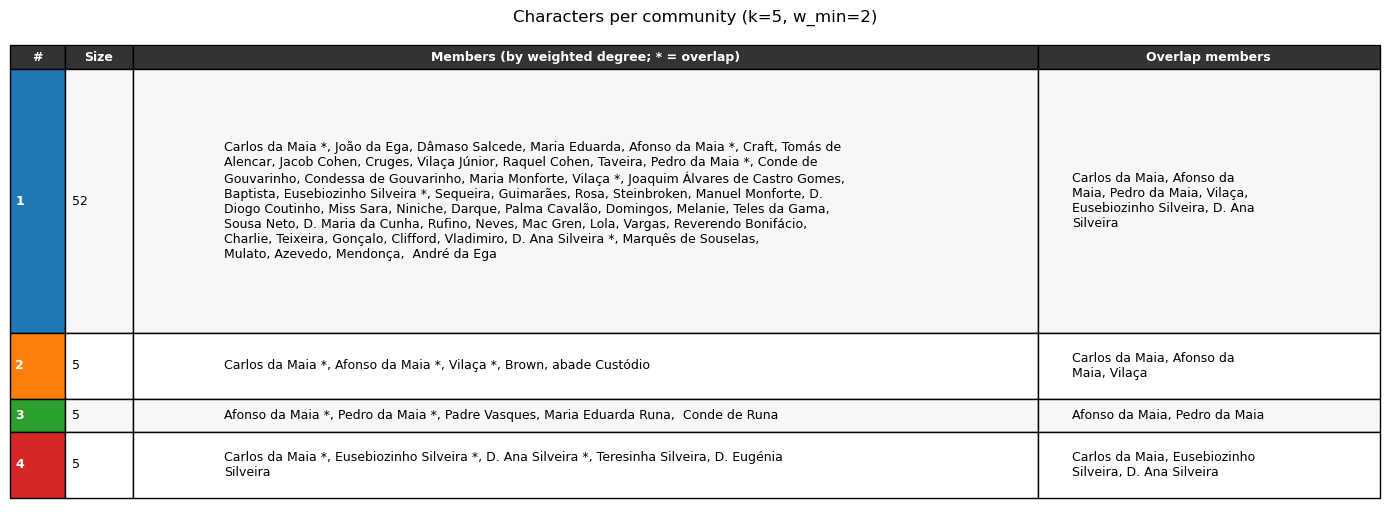

In [ ]:
from community_viz import plot_communities_clean, community_tables, plot_community_table
from communities import threshold_graph

K, W_MIN = 5,2
                     # or 5, 2
H = threshold_graph(G, W_MIN)

fig, ax, pos = plot_communities_clean(
    G, H, K, W_MIN, name_map,
    community_names={1: "fam e amigos recentes", 2: "familia de infancia", 3: "familia pre carlos", 4:"vizinhos da infacia"},   # optional: your own legend names
)
fig.savefig(f"network_k{K}_w{W_MIN}.png", dpi=200, bbox_inches="tight")
plt.show()

summary_df, long_df = community_tables(H, K, name_map)
display(summary_df)
fig, ax = plot_community_table(summary_df, K, W_MIN)
plt.show()

k= 8, w = 3


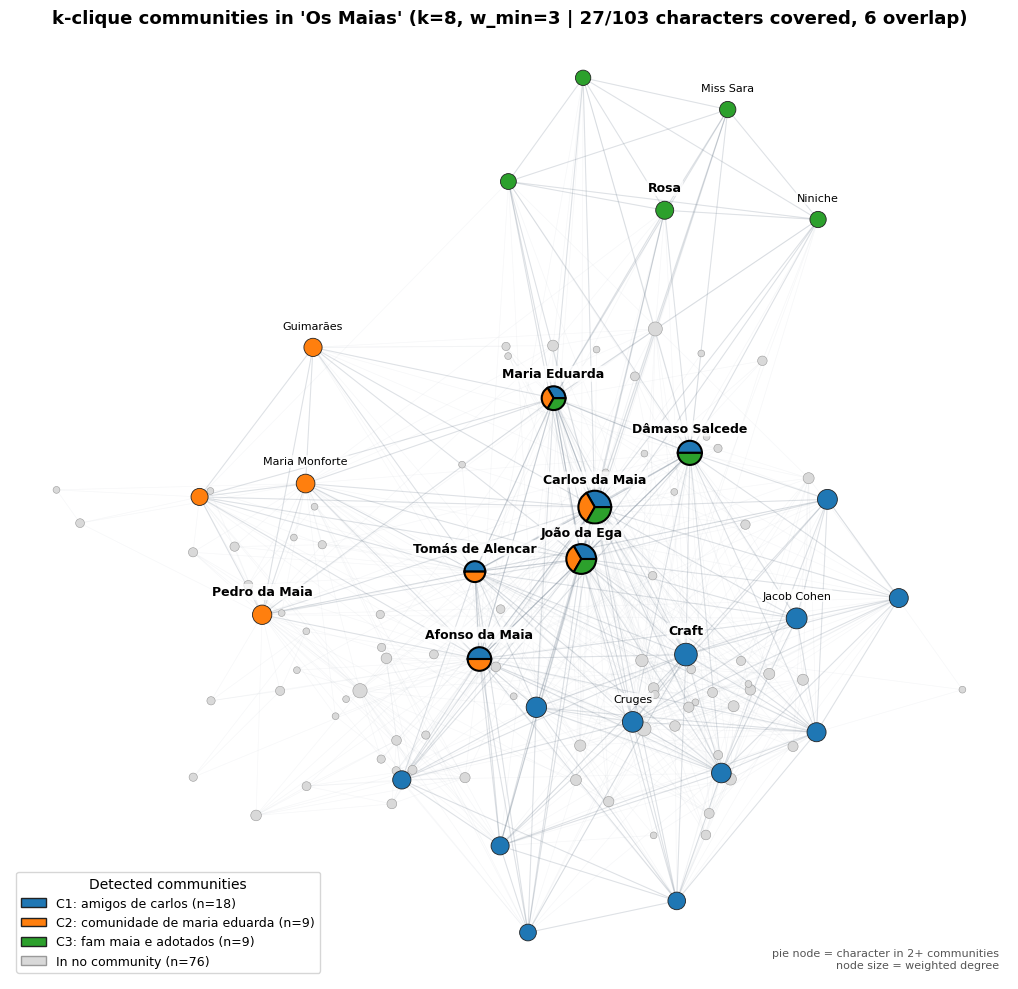

,community,size,members (by weighted degree),overlap members
0,1,18,"Carlos da Maia *, João da Ega *, Dâmaso Salced...","Carlos da Maia, João da Ega, Dâmaso Salcede, M..."
1,2,9,"Carlos da Maia *, João da Ega *, Maria Eduarda...","Carlos da Maia, João da Ega, Maria Eduarda, Af..."
2,3,9,"Carlos da Maia *, João da Ega *, Dâmaso Salced...","Carlos da Maia, João da Ega, Dâmaso Salcede, M..."


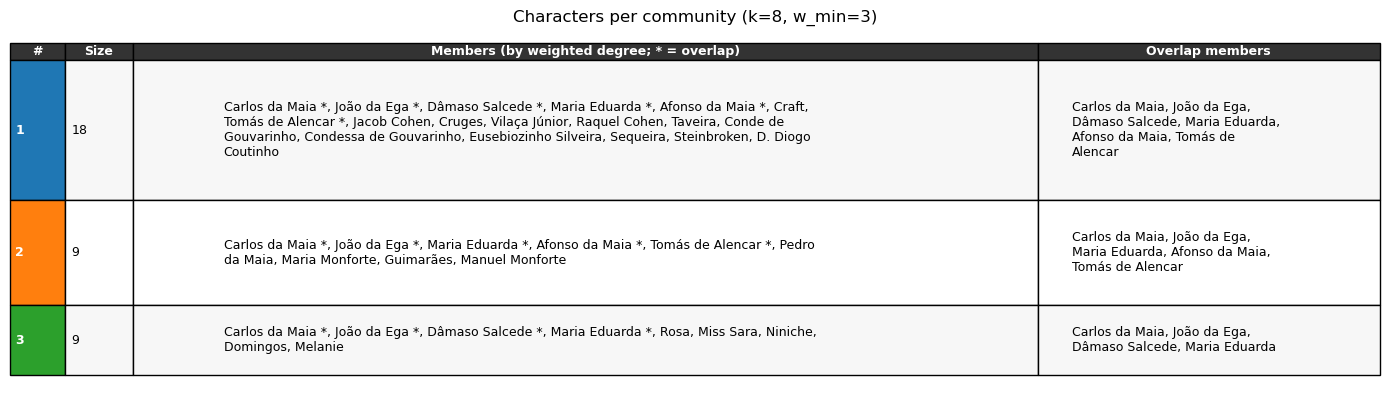

In [ ]:
from community_viz import plot_communities_clean, community_tables, plot_community_table
from communities import threshold_graph

K, W_MIN = 8, 3                      # or 5, 2
H = threshold_graph(G, W_MIN)

fig, ax, pos = plot_communities_clean(
    G, H, K, W_MIN, name_map,
    community_names={1: "amigos de carlos", 2: "comunidade de maria eduarda", 3: "fam maia e adotados"},   # optional: your own legend names
)
fig.savefig(f"network_k{K}_w{W_MIN}.png", dpi=200, bbox_inches="tight")
plt.show()

summary_df, long_df = community_tables(H, K, name_map)
display(summary_df)
fig, ax = plot_community_table(summary_df, K, W_MIN)
plt.show()